# Amazing Creative Desk Coworking (ACDC) 

## The Data


## Objective
To understand the structure of the dataset, flag any potential issues or redundancies and to further understand which features of the dataset could support useful member segmentation allowing for effective clustering. 



| Segmentation perspective | Business question | Evidence to inspect |
| --- | --- | --- |
| Economic value | Who contributes the most revenue, and is this just longer exposure? | Lifetime value, elapsed membership time, renewals, plan |
| Attendance behavior | Who visits frequently, underuses their allowance, or has not visited recently? | Weekly visits, last-period utilization, consistently dated recency |
| Service preferences | Which add-ons distinguish workspace needs? | Service adoption, room hours, guest passes |
| Context / profiling | Do team accounts and plans have different profiles? | Group counts, medians, conditional proportions |

In [130]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import matplotlib as mpl
from statsmodels.stats.outliers_influence import variance_inflation_factor
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

BLUE = "#5EDDF3"
ORANGE = "#F78441"
GRAY = "#8E9196"
mpl.rcParams["figure.dpi"] = 110
mpl.rcParams["axes.spines.top"] = False
mpl.rcParams["axes.spines.right"] = False
mpl.rcParams["font.size"] = 10.5

from pathlib import Path

RAW_PATH = "../data/acdc_dataset.csv"
df_raw = pd.read_csv(RAW_PATH, sep=";")
print(df_raw.shape)
df_raw.head(10)

(15465, 31)


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,2023-03-23,-17,220,2.65,26.09,22,0.0,0.0,18.0,False,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,2023-11-24,37,2,0.32,10.68,1,0.0,0.0,0.0,False,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,2023-07-22,163,19,0.17,26.09,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,2022-01-02,44,8,1.23,18.74,9,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,2023-12-17,15,4,0.38,17.39,3,0.0,0.0,0.0,False,False,False,0,False,False,True,False,False,0,335.74
5,CW000006,39.0,Male,Health,Portugal,False,0,flex,3,2021-05-31,2021-08-01,2021-07-09,23,3,0.36,26.09,3,0.0,0.0,0.0,False,False,False,1,True,False,False,False,False,0,413.17
6,CW000007,23.0,Female,Unknown,Portugal,True,2,hot_desk,2,2022-01-17,2022-03-19,2022-01-31,47,5,0.62,17.39,5,0.0,0.0,1.0,False,False,True,0,False,False,False,False,False,0,257.95
7,CW000008,33.0,Male,Information Technology,Portugal,True,3,flex,3,2021-03-28,2022-06-30,2022-06-14,16,155,2.36,26.09,25,129.0,0.0,0.0,True,False,False,0,False,False,False,True,False,0,4636.8
8,CW000009,30.0,Male,Other,Portugal,False,0,flex,3,2023-08-12,2023-09-21,2023-08-12,40,6,1.10,17.13,6,0.0,1.0,0.0,False,True,False,0,False,False,False,False,False,0,281.37
9,CW000010,44.0,Male,Consulting,Portugal,False,0,dedicated_desk,5,2022-06-06,1970-01-01,2023-12-30,2,331,4.04,43.48,36,42.1,0.0,37.0,True,False,True,1,True,True,False,True,False,1,8741.88


## Metadata Analysis
The following descriptions of columns have been taken from the project guidelines. The expected type of the data, a description of the vatribale and a interpretation risk column have all been included. Note that this dictionary was generated with AI and is in our  [AI Usage Disclaimer](../AI_USAGE.md)


In [38]:
dictionary_rows = [
    ('member_id', 'Identifier', 'Unique member identifier', 'Exclude from distances'),
    ('age', 'Numeric', 'Age at extraction', 'Review implausible ages; not birth year'),
    ('gender', 'Categorical', 'Reported gender', 'Profiling context; not default distance input'),
    ('industry', 'Categorical', 'Member industry', 'Normalize aliases; preserve Unknown category'),
    ('country', 'Categorical', 'Member/company country', 'Normalize country aliases'),
    ('is_team_account', 'Binary', 'Team/company account indicator', 'Account-level quantities need interpretation'),
    ('n_colleagues_on_account', 'Numeric', 'Colleagues sharing the account', 'Nonnegative; check team consistency'),
    ('plan_tier', 'Ordinal categorical', 'hot_desk < flex < dedicated_desk < full_time < private_office', 'Order is not equal numerical spacing'),
    ('plan_days_per_week', 'Numeric', 'Weekly entitled attendance days', 'Review zero; cannot exceed seven'),
    ('membership_start', 'Date', 'First membership start', 'Mixed ISO and day/month/year formats'),
    ('membership_end', 'Date', 'First membership end', '1970-01-01 treated as a candidate sentinel'),
    ('last_badge_swipe', 'Date', 'Most recent physical entry', 'Check against start and reference date'),
    ('days_since_last_visit', 'Numeric', 'Reported visit recency', 'Audit mixed reference dates before use'),
    ('total_visits', 'Numeric', 'Visits over the whole membership', 'Nonnegative count; exposure dependence'),
    ('avg_weekly_visits', 'Numeric', 'Average weekly visits over membership', 'Continuous average, not an integer count'),
    ('entitled_visits_last_period', 'Numeric', 'Entitled visits during last membership period', 'Denominator can be zero'),
    ('actual_visits_last_period', 'Numeric', 'Actual visits during last membership period', 'Can exceed entitlement; do not cap automatically'),
    ('meeting_room_hours', 'Numeric', 'Recorded meeting-room hours', 'Missing is not zero'),
    ('event_space_hours', 'Numeric', 'Recorded event-space hours', 'Zero-heavy; review extremes'),
    ('guest_passes_issued', 'Numeric', 'Guest passes issued', 'Missing is not zero'),
    ('uses_meeting_rooms', 'Binary', 'Ever used meeting-room add-on', 'Cross-check hours; time scope may differ'),
    ('uses_event_space', 'Binary', 'Ever used event-space add-on', 'Cross-check hours; time scope may differ'),
    ('uses_guest_passes', 'Binary', 'Ever used guest-pass add-on', 'Cross-check passes; time scope may differ'),
    ('uses_print', 'Binary', 'Used print add-on', 'Stored as 0/1 rather than True/False'),
    ('uses_mail_handling', 'Binary', 'Used mail-handling add-on', 'Keep nullable Boolean type'),
    ('uses_phone_booths', 'Binary', 'Used phone-booth add-on', 'Keep nullable Boolean type'),
    ('uses_day_passes', 'Binary', 'Used day-pass add-on', 'Keep nullable Boolean type'),
    ('uses_storage', 'Binary', 'Used storage add-on', 'Keep nullable Boolean type'),
    ('uses_bike_locker', 'Binary', 'Used bike-locker add-on', 'Rare does not mean erroneous'),
    ('n_renewals', 'Numeric', 'Number of renewals', 'Nonnegative integer; first end is not final churn'),
    ('lifetime_value', 'Numeric', 'Total attributed member revenue', 'Mixed currency formatting; zeros are not missing'),
]
data_dictionary = pd.DataFrame(dictionary_rows, columns=['feature', 'role', 'meaning', 'interpretation_risk'])

display(data_dictionary)


,feature,role,meaning,interpretation_risk
0,member_id,Identifier,Unique member identifier,Exclude from distances
1,age,Numeric,Age at extraction,Review implausible ages; not birth year
2,gender,Categorical,Reported gender,Profiling context; not default distance input
3,industry,Categorical,Member industry,Normalize aliases; preserve Unknown category
4,country,Categorical,Member/company country,Normalize country aliases
5,is_team_account,Binary,Team/company account indicator,Account-level quantities need interpretation
6,n_colleagues_on_account,Numeric,Colleagues sharing the account,Nonnegative; check team consistency
7,plan_tier,Ordinal categorical,hot_desk < flex < dedicated_desk < full_time <...,Order is not equal numerical spacing
8,plan_days_per_week,Numeric,Weekly entitled attendance days,Review zero; cannot exceed seven
9,membership_start,Date,First membership start,Mixed ISO and day/month/year formats


# Initial Analysis
In this section, it is aimed to inspect the shape, storage types, missing values, unique values of both numerical and categorical variables. This initial analysis will set the foundation for modifying data later. Incongruencies will be flagged and saved in [diagnosis.yaml](../diagnosis.yaml)

### 1. Replacing `.info()`

The following cell is a more comprehensive view tahn `.info()`. It contains a total value and proportional view of missing values, in addition to the `dtypes` of each variable and number of unique values (excluding missing).

In [39]:
raw_profile = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'expected_type': data_dictionary.set_index('feature')['role'].reindex(df_raw.columns),
    'missing_n': df_raw.isna().sum(),
    'missing_pct': round((df_raw.isna().sum() / len(df_raw)) * 100, 2),
    'distinct_non_missing': df_raw.nunique(),
})
display(raw_profile)

,dtype,expected_type,missing_n,missing_pct,distinct_non_missing
member_id,object,Identifier,0,0.00,15450
age,float64,Numeric,558,3.61,84
gender,object,Categorical,530,3.43,12
industry,object,Categorical,0,0.00,43
country,object,Categorical,430,2.78,33
is_team_account,bool,Binary,0,0.00,2
n_colleagues_on_account,int64,Numeric,0,0.00,11
plan_tier,object,Ordinal categorical,105,0.68,19
plan_days_per_week,int64,Numeric,0,0.00,6
membership_start,object,Date,0,0.00,1539


In [124]:
# Checking Unique Values and Types of uses_print
print("1. uses_print:")
print({(val, type(val)) for val in df_raw["uses_print"].unique()})
print()

print("2. guest_passes_issued:")

# Checking Types of lifetime_value
print({type(val) for val in df_raw["guest_passes_issued"].unique()})

# Checking if Data Contains Decimals
print(df_raw["guest_passes_issued"][:5])

print()


print("3. lifetime_value:")

# Checking Types of lifetime_value
print({type(val) for val in df_raw["lifetime_value"].unique()})

# Checking if Data Contains Decimals
print(df_raw["lifetime_value"][:5])

# Checking Float value in lifetime_value
print({val for val in df_raw["lifetime_value"] if isinstance(val, float)})

print()

print("3. lifetime_value:")

# Checking Types of lifetime_value
print({type(val) for val in df_raw["membership_start"].unique()})
print({type(val) for val in df_raw["membership_end"].unique()})
print({type(val) for val in df_raw["last_badge_swipe"].unique()})

print(df_raw["membership_start"][:5])



1. uses_print:
{(0, <class 'numpy.int64'>), (1, <class 'numpy.int64'>)}

2. guest_passes_issued:
{<class 'numpy.float64'>}
0    18.0
1     0.0
2     0.0
3     0.0
4     0.0
Name: guest_passes_issued, dtype: float64

3. lifetime_value:
{<class 'float'>, <class 'str'>}
0    4477.97
1     165.86
2    4486.17
3     258.63
4     335.74
Name: lifetime_value, dtype: object
{nan}

3. lifetime_value:
{<class 'str'>}
{<class 'str'>}
{<class 'str'>}
0    2021-08-01
1    2023-11-24
2    2021-12-03
3    2022-01-02
4    2023-10-24
Name: membership_start, dtype: object


### 1.1 Incongruent Types
Data types were inspected further due to their expected type differing from actual type:
1. **uses_print** 
    - Variable needs to be updated from integer to boolean
2. **guest_passes_issued**
    - Variable need to be updated from float to int
3. **lifetime_value**
    - Variable need to be updated from string to float
4. **membership_start, membership_end, last_badge_swipe**
    - Variables need to be updated from object to date

Note: incongruent types are being changed to their expected type to continue this analysis. This is a local change, final changes will be execute later. 

In [128]:
# Work on a copy
df_clean = df_raw.copy()

# 1. uses_print: integer -> nullable boolean
df_clean["uses_print"] = df_clean["uses_print"].astype("boolean")

# 2. guest_passes_issued: float -> nullable integer
df_clean["guest_passes_issued"] = (
    df_clean["guest_passes_issued"].astype("Int64")
)

# 3. lifetime_value: currency string -> nullable float
lifetime_value = (
    df_clean["lifetime_value"]
    .astype("string")
    .str.replace("€", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["lifetime_value"] = pd.to_numeric(
    lifetime_value, errors="raise"
).astype("Float64")


# 4. dates: strings -> dates
date_features = ['membership_start', 'membership_end', 'last_badge_swipe']

for feature in date_features:
    tokens = df_clean[feature].astype("string").str.strip()

    parsed = pd.Series(
        pd.NaT, index=df_clean.index, dtype="datetime64[ns]"
    )

    iso_mask = tokens.str.fullmatch(r"\d{4}-\d{2}-\d{2}", na=False)
    slash_mask = tokens.str.fullmatch(r"\d{2}/\d{2}/\d{4}", na=False)

    parsed.loc[iso_mask] = pd.to_datetime(
        tokens.loc[iso_mask], format="%Y-%m-%d", errors="coerce"
    )
    parsed.loc[slash_mask] = pd.to_datetime(
        tokens.loc[slash_mask], format="%d/%m/%Y", errors="coerce"
    )

    invalid = tokens.notna() & parsed.isna()

    if invalid.any():
        raise ValueError(
            f"Invalid dates in {feature}: "
            f"{tokens.loc[invalid].unique().tolist()}"
        )

    df_clean[feature] = parsed

print(df_clean[
    ["uses_print", "guest_passes_issued", "lifetime_value"] + date_features
].dtypes)




uses_print                    boolean
guest_passes_issued             Int64
lifetime_value                Float64
membership_start       datetime64[ns]
membership_end         datetime64[ns]
last_badge_swipe       datetime64[ns]
dtype: object


### 1.2 Missingness 
Variables with large proportion of missing values include
1. **meeting_room_hours**
2. **guest_passes_issued**
3. **lifetime_value**

Note that a missigness analysis will take place in a [REFERENCE SECTION]. To determine whether missing values have correlations. 

### 2. Numerical Boundaries
Realistic bounds are defined for numerical variables to identify values that fall outside their valid or plausible ranges. These checks help detect potential data entry errors, inconsistent units, and invalid values that could affect the analysis. 

In [109]:
display(round(df_clean.describe().T, 2))
display(df_clean.describe(include=['object', 'bool']).T)

# Inclusive validity bounds, not observed minima/maxima; None means no fixed limit.
# Age bounds are provisional review thresholds, not automatic deletion rules.
range_bounds = {
    'age': (18, 100),
    'n_colleagues_on_account': (0, None),
    'plan_days_per_week': (0, 7),
    'days_since_last_visit': (0, None),
    'total_visits': (0, None),
    'avg_weekly_visits': (0, None),
    'entitled_visits_last_period': (0, None),
    'actual_visits_last_period': (0, None),
    'meeting_room_hours': (0, None),
    'event_space_hours': (0, None),
    'guest_passes_issued': (0, None),
    'uses_print': (0, 1),
    'n_renewals': (0, None),
    'lifetime_value': (None, None), # Check this bound, should it be unbound?
}

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.0,34.0,40.0,149.0
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.0,0.0,1.0,9.0
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.0,3.0,5.0,9.0
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.0,13.0,55.0,1212.0
total_visits,15465.0,110.406531,182.93934,-112.0,8.0,34.0,132.0,6530.0
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.4
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.80097,11.387207,0.0,5.0,10.0,20.0,60.0
meeting_room_hours,14167.0,33.07557,428.169678,-56.6,0.0,0.0,7.2,41220.0
event_space_hours,15465.0,5.11722,26.013097,-13.5,0.0,0.0,0.0,602.8


,count,unique,top,freq
member_id,15465,15450,CW005845,2
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
is_team_account,15465,2,False,11112
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
uses_meeting_rooms,15465,2,False,10202


### 2.2 Duplicates
There is a frequency of two for member_id which indicates that there are duplicates.

In [ ]:
# Check for duplicates 
print(df_clean.duplicated().sum())
print(df_clean["member_id"].duplicated().sum())

15
15


In [ ]:
# Drop duplicates
df_clean = df_clean.copy()
df_clean = df_clean.drop_duplicates()

### 3. Canotical Mapping
Canonical mapping standardises different representations of the same category into a single, consistent label. Differences in spelling, capitalisation, whitespace, or abbreviations can cause equivalent values to be treated as separate categories during analysis.

In [ ]:
category_columns = data_dictionary[data_dictionary["role"].str.contains(
    "Categorical", case=False, na=False, regex=False
    )]["feature"]


for feature in category_columns:
    display(df_raw[feature].value_counts(dropna=False))


gender
Female     7414
Male       6172
NaN         530
Other       465
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        9
O             8
Name: count, dtype: int64

industry
Information Technology    3322
Consulting                1896
Marketing & PR            1835
Design & Creative         1822
Finance                   1134
Other                     1100
Legal                      809
Education                  727
Unknown                    640
Health                     571
Real Estate                528
CONSULTING                  86
consulting                  76
INFORMATION TECHNOLOGY      54
IT                          53
information technology      49
FINANCE                     48
design & creative           44
Information technology      41
Tech                        40
DESIGN & CREATIVE           40
OTHER                       39
LEGAL                       38
finance                     38
other                       36
Design/Creative             35
Design and Creative         34
legal                       33
MARKETING & PR              32
UNKNOWN                     29
unknown                     27
marketing & pr              25

country
Portugal           9959
United Kingdom     1105
Germany             852
Spain               712
France              506
Netherlands         464
NaN                 430
Other (Europe)      429
Ireland             232
portugal            155
Portucal            142
PT                  130
portugal            122
germany              24
other (europe)       22
france               18
united kingdom       16
UK                   14
DE                   14
NL                   13
Deutschland          13
GB                   12
U.K.                 10
Espana               10
United kingdom        9
FR                    9
ES                    8
España                7
ireland               6
IE                    6
spain                 5
netherlands           4
The Netherlands       4
Holland               3
Name: count, dtype: int64

plan_tier
flex              5182
hot_desk          4974
full_time         2323
dedicated_desk    1481
private_office     630
Flex               138
FLEX               133
NaN                105
HOT_DESK            82
Hot Desk            80
hotdesk             79
fulltime            64
FULL_TIME           49
Full Time           39
DEDICATED_DESK      27
Dedicated Desk      25
dedicateddesk       19
Private Office      13
privateoffice       12
PRIVATE_OFFICE      10
Name: count, dtype: int64

In [113]:
def canonicalize_labels(series, aliases):
    keys = series.astype('string').str.strip().str.replace(r'\s+', ' ', regex=True).str.casefold()
    return keys.map(aliases).fillna(keys.str.title()).astype('string')

gender_aliases = {'f': 'Female', 'female': 'Female', 'm': 'Male', 'male': 'Male', 'o': 'Other', 'other': 'Other'}
country_aliases = {
    'pt': 'Portugal', 'portugal': 'Portugal', 'portucal': 'Portugal',
    'uk': 'United Kingdom', 'u.k.': 'United Kingdom', 'gb': 'United Kingdom', 'united kingdom': 'United Kingdom',
    'de': 'Germany', 'germany': 'Germany', 'deutschland': 'Germany',
    'es': 'Spain', 'spain': 'Spain', 'espana': 'Spain', 'españa': 'Spain',
    'fr': 'France', 'france': 'France',
    'nl': 'Netherlands', 'netherlands': 'Netherlands', 'the netherlands': 'Netherlands', 'holland': 'Netherlands',
    'ie': 'Ireland', 'ireland': 'Ireland', 'other (europe)': 'Other (Europe)',
}
industry_aliases = {
    'it': 'Information Technology', 'tech': 'Information Technology', 'information technology': 'Information Technology',
    'marketing & pr': 'Marketing & PR', 'marketing/pr': 'Marketing & PR', 'marketing and pr': 'Marketing & PR',
    'design & creative': 'Design & Creative', 'design/creative': 'Design & Creative', 'design and creative': 'Design & Creative',
    'real estate': 'Real Estate', 'real-estate': 'Real Estate', 'realestate': 'Real Estate',
}

plan_order = ['hot_desk', 'flex', 'dedicated_desk', 'full_time', 'private_office']

plan_tier_aliases = {
    "flex": "flex",
    "hot_desk": "hot_desk",
    "hot desk": "hot_desk",
    "hotdesk": "hot_desk",
    "full_time": "full_time",
    "full time": "full_time",
    "fulltime": "full_time",
    "dedicated_desk": "dedicated_desk",
    "dedicated desk": "dedicated_desk",
    "dedicateddesk": "dedicated_desk",
    "private_office": "private_office",
    "private office": "private_office",
    "privateoffice": "private_office",
}

column_aliases = {
    "gender": gender_aliases,
    "country": country_aliases,
    "industry": industry_aliases,
    "plan_tier": plan_tier_aliases,
}

for column, aliases in column_aliases.items():
    df_clean[column] = canonicalize_labels(df_clean[column], aliases)

In [ ]:

plan_order = [
    "hot_desk",
    "flex",
    "dedicated_desk",
    "full_time",
    "private_office",
]

df_clean["plan_tier"] = pd.Categorical(
    df_clean["plan_tier"],
    categories=plan_order,
    ordered=True,
)

## 4. Missingness


,missing_count,missing_pct,observed_count
meeting_room_hours,1298,8.39,14167
guest_passes_issued,1271,8.22,14194
lifetime_value,1040,6.72,14425
age,558,3.61,14907
gender,530,3.43,14935
country,430,2.78,15035
plan_tier,105,0.68,15360


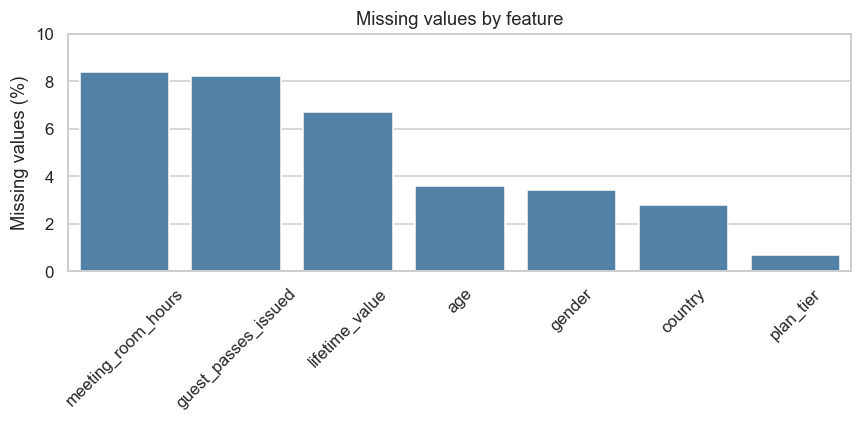

In [145]:

sns.set_theme(style="whitegrid")

cols = df_clean.columns

missing = df_clean[cols].isna()


summary = pd.DataFrame({
    "missing_count": missing.sum(),
    "missing_pct": missing.mean().mul(100),
    "observed_count": (~missing).sum(),
})

summary = (
    summary.loc[summary["missing_count"] > 0]
    .sort_values("missing_pct", ascending=False)
)

display(summary.round(2))

fig, ax = plt.subplots(figsize=(8, 4))

sns.barplot(
    data=summary.reset_index(names="feature"),
    x="feature",
    y="missing_pct",
    color="steelblue",
    ax=ax,
)

ax.set(
    title="Missing values by feature",
    xlabel="",
    ylabel="Missing values (%)",
    ylim=(0, 10),
)

ax.tick_params(axis="x", labelrotation=45)

plt.tight_layout()
plt.show()


# EVERYTHING AFTER THIS POINT IS DRAFT MATERIAL WHICH MAY BE USED AT A LATER STAGE

In [ ]:
missingness = pd.DataFrame({
    'raw_missing_n': df_clean.isna().sum(),
    'canonical_missing_n': df_clean.isna().sum(),
    'canonical_missing_pct': df.isna().mean().mul(100),
}).sort_values('canonical_missing_pct', ascending=False)
display(missingness.loc[missingness['canonical_missing_n'].gt(0) | missingness['raw_missing_n'].gt(0)])

missing_columns = missingness.index[missingness['canonical_missing_n'].gt(0)].tolist()
figure, axes = plt.subplots(1, 2, figsize=(15, 5))
missingness.loc[missing_columns, 'canonical_missing_pct'].sort_values().plot.barh(ax=axes[0], color='#0072B2')
axes[0].set(xlabel='Missing observations (%)', title='Missingness after representation cleanup')
sample_missing = df[missing_columns].sample(min(400, len(df)), random_state=RANDOM_STATE).isna()
sns.heatmap(sample_missing, cbar=False, yticklabels=False, cmap=['#E8EEF2', '#D55E00'], ax=axes[1])
axes[1].set(title='Missingness pattern: fixed random sample', ylabel='Sampled member rows')
figure.tight_layout()
finish_figure(figure, '01_missingness')

In [75]:
def cramers_v(confusion_matrix: pd.DataFrame) -> float:
    """Bias-corrected Cramer's V effect size for a chi-square test of association."""
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)
    return float(np.sqrt(phi2_corr / min(k_corr - 1, r_corr - 1)))


def test_missingness_mechanism(df: pd.DataFrame, target_col: str, candidate_predictors: list) -> pd.DataFrame:
    """
    For `target_col`'s missing-value indicator, test association against each
    column in `candidate_predictors` via chi-square + Cramer's V.
    Returns one row per predictor, sorted by association strength (strongest first).
    """
    indicator = df[target_col].isna()
    rows = []
    for predictor in candidate_predictors:
        if predictor == target_col:
            continue
        sub = pd.DataFrame({"missing": indicator, "predictor": df[predictor]}).dropna(subset=["predictor"])
        if sub["predictor"].nunique() < 2 or sub["missing"].nunique() < 2:
            continue
        table = pd.crosstab(sub["missing"], sub["predictor"])
        chi2, p, _, _ = chi2_contingency(table)
        v = cramers_v(table)
        rows.append({"predictor": predictor, "cramers_v": round(v, 3), "p_value": p, "n": len(sub)})
    result = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)
    return result


def verdict_from_max_v(max_v: float) -> str:
    if max_v >= 0.2:
        return "MAR / MNAR (possible pattern)"
    elif max_v >= 0.1:
        return "borderline -- worth a closer look"
    else:
        return "MCAR (scattered, no pattern found)"


In [76]:
df_raw.columns

Index(['member_id', 'age', 'gender', 'industry', 'country', 'is_team_account', 'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week', 'membership_start', 'membership_end', 'last_badge_swipe', 'days_since_last_visit', 'total_visits',
       'avg_weekly_visits', 'entitled_visits_last_period', 'actual_visits_last_period', 'meeting_room_hours', 'event_space_hours', 'guest_passes_issued', 'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes', 'uses_print',
       'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals', 'lifetime_value'],
      dtype='object')

In [77]:
candidate_predictors = ['member_id', 'age', 'gender', 'industry', 'country', 'is_team_account', 'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week', 'membership_start', 'membership_end', 'last_badge_swipe', 'days_since_last_visit', 'total_visits',
       'avg_weekly_visits', 'entitled_visits_last_period', 'actual_visits_last_period', 'meeting_room_hours', 'event_space_hours', 'guest_passes_issued', 'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes', 'uses_print',
       'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals', 'lifetime_value']
raw_missing_cols = [c for c in ['member_id', 'age', 'gender', 'industry', 'country', 'is_team_account', 'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week', 'membership_start', 'membership_end', 'last_badge_swipe', 'days_since_last_visit', 'total_visits',
       'avg_weekly_visits', 'entitled_visits_last_period', 'actual_visits_last_period', 'meeting_room_hours', 'event_space_hours', 'guest_passes_issued', 'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes', 'uses_print',
       'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals', 'lifetime_value']
                     if df_raw[c].isna().any()]

first_pass_results = {}
for col in raw_missing_cols:
    preds = [p for p in candidate_predictors if p != col]
    first_pass_results[col] = test_missingness_mechanism(df_raw, col, preds)
    print(f"=== {col} (n missing = {df_raw[col].isna().sum()}) ===")
    print(first_pass_results[col])
    print()

=== age (n missing = 558) ===
                      predictor  cramers_v       p_value      n
0   entitled_visits_last_period      0.192  7.010567e-18  15465
1                  total_visits      0.084  4.765537e-03  15465
2             event_space_hours      0.080  8.943852e-03  15465
3              membership_start      0.062  1.449198e-01  15465
4         days_since_last_visit      0.061  2.733878e-02  15465
5             avg_weekly_visits      0.049  1.412238e-01  15465
6     actual_visits_last_period      0.034  6.099416e-02  15465
7                     member_id      0.031  4.622429e-01  15465
8                       country      0.027  9.950157e-02  15035
9            meeting_room_hours      0.024  4.425306e-01  14167
10                     industry      0.018  2.687362e-01  15465
11             uses_event_space      0.016  2.300429e-02  15465
12              is_team_account      0.013  6.237404e-02  15465
13                   uses_print      0.004  2.591959e-01  15465
14        

In [78]:
first_pass_verdicts = pd.DataFrame([
    {
        "column": col,
        "strongest_predictor": res.iloc[0]["predictor"] if len(res) else None,
        "max_cramers_v": res.iloc[0]["cramers_v"] if len(res) else None,
        "verdict": verdict_from_max_v(res.iloc[0]["cramers_v"] if len(res) else 0.0),
    }
    for col, res in first_pass_results.items()
])
first_pass_verdicts

,column,strongest_predictor,max_cramers_v,verdict
0,age,entitled_visits_last_period,0.192,borderline -- worth a closer look
1,gender,guest_passes_issued,0.112,borderline -- worth a closer look
2,country,avg_weekly_visits,0.067,"MCAR (scattered, no pattern found)"
3,plan_tier,meeting_room_hours,0.397,MAR / MNAR (possible pattern)
4,meeting_room_hours,entitled_visits_last_period,0.184,borderline -- worth a closer look
5,guest_passes_issued,entitled_visits_last_period,0.167,borderline -- worth a closer look
6,lifetime_value,meeting_room_hours,0.280,MAR / MNAR (possible pattern)


In [79]:

df = df_raw.copy()


print("Negative ages:", (df["age"] < 0).sum())
print("Ages below 18:", (df["age"] < 18).sum())
print("Missing ages:", df["age"].isna().sum())
print("Minimum age:", df["age"].min())
print("Maximum age:", df["age"].max())

Negative ages: 0
Ages below 18: 98
Missing ages: 558
Minimum age: 1.0
Maximum age: 149.0


In [80]:

numeric_columns = df.select_dtypes(include=["int64", "float64"]).columns

summary = df[numeric_columns].describe().T

print(summary)

                               count        mean         std    min    25%    50%     75%       max
age                          14907.0   34.858724   10.394649    1.0  29.00  34.00   40.00    149.00
n_colleagues_on_account      15465.0    0.537019    1.177668   -1.0   0.00   0.00    1.00      9.00
plan_days_per_week           15465.0    3.387262    1.458818    0.0   2.00   3.00    5.00      9.00
days_since_last_visit        15465.0  117.109279  275.532807 -956.0   4.00  13.00   55.00   1212.00
total_visits                 15465.0  110.406531  182.939340 -112.0   8.00  34.00  132.00   6530.00
avg_weekly_visits            15465.0    1.777214    1.937515    0.0   0.71   1.42    2.41     47.40
entitled_visits_last_period  15465.0   27.517393   13.480235    0.0  17.39  26.09   43.48     78.27
actual_visits_last_period    15465.0   13.800970   11.387207    0.0   5.00  10.00   20.00     60.00
meeting_room_hours           14167.0   33.075570  428.169678  -56.6   0.00   0.00    7.20  41220.00


In [81]:


def domain_rule_report(df: pd.DataFrame, feat: str, min_val: int, max_val: int) -> pd.DataFrame:
    rows = []
    # age: implausible if outside a plausible adult defendant range
    feat_num = pd.to_numeric(df[feat], errors="coerce")
    bad_val = df[feat].notna() & ~feat_num.between(min_val, max_val)
    rows.append({"column": feat, "rule": f"{min_val} <= {feat} <= {max_val}", "violations": int(bad_val.sum()),
                 "examples": sorted(feat_num[bad_val].unique().tolist())[:6]})


    return pd.DataFrame(rows)

for col in numeric_columns:
    print(f"=== {col} ===")
    print(domain_rule_report(df, col, 0, 100))
    print()



=== age ===
  column             rule  violations                                    examples
0    age  0 <= age <= 100          45  [131.0, 132.0, 134.0, 135.0, 136.0, 137.0]

=== n_colleagues_on_account ===
                    column                                 rule  violations examples
0  n_colleagues_on_account  0 <= n_colleagues_on_account <= 100         566     [-1]

=== plan_days_per_week ===
               column                            rule  violations examples
0  plan_days_per_week  0 <= plan_days_per_week <= 100           0       []

=== days_since_last_visit ===
                  column                               rule  violations                              examples
0  days_since_last_visit  0 <= days_since_last_visit <= 100        2691  [-956, -903, -805, -779, -734, -721]

=== total_visits ===
         column                      rule  violations                          examples
0  total_visits  0 <= total_visits <= 100        4950  [-112, -102, -88, -77, -75,

In [82]:
df = pd.read_csv(RAW_PATH, sep=";")

df.head(5)

df.columns

df.info()

df.describe()

df.dtypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  object 
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  object 
 3   industry                     15465 non-null  object 
 4   country                      15035 non-null  object 
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  object 
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  object 
 10  membership_end               15465 non-null  object 
 11  last_badge_swipe             15465 non-null  object 
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits    

member_id                       object
age                            float64
gender                          object
industry                        object
country                         object
is_team_account                   bool
n_colleagues_on_account          int64
plan_tier                       object
plan_days_per_week               int64
membership_start                object
membership_end                  object
last_badge_swipe                object
days_since_last_visit            int64
total_visits                     int64
avg_weekly_visits              float64
entitled_visits_last_period    float64
actual_visits_last_period        int64
meeting_room_hours             float64
event_space_hours              float64
guest_passes_issued            float64
uses_meeting_rooms                bool
uses_event_space                  bool
uses_guest_passes                 bool
uses_print                       int64
uses_mail_handling                bool
uses_phone_booths        

In [83]:
df.isnull().sum()

for col in df.columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))
    


member_id:
member_id
CW005845    2
CW009828    2
CW001390    2
CW006678    2
CW012056    2
           ..
CW005007    1
CW005008    1
CW005009    1
CW005010    1
CW015000    1
Name: count, Length: 15450, dtype: int64

age:
age
34.0     710
31.0     679
32.0     658
36.0     655
35.0     650
        ... 
143.0      1
139.0      1
91.0       1
149.0      1
147.0      1
Name: count, Length: 85, dtype: int64

gender:
gender
Female     7414
Male       6172
NaN         530
Other       465
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        9
O             8
Name: count, dtype: int64

industry:
industry
Information Technology    3322
Consulting                1896
Marketing & PR            1835
Design & Creative         1822
Finance                   1134
Other                     1100
Legal                      809
Education                  727
Unknown                    640
Health                     571
Real Estate 

In [84]:
for col in df.columns:
    print(f"\n{col}:")
    print(df[col].unique())


member_id:
['CW000001' 'CW000002' 'CW000003' ... 'CW014998' 'CW014999' 'CW015000']

age:
[ 38.  43.  45.  39.  23.  33.  30.  44.  37. 131.  20.  40.  32.  21.
  29.  25.  28.  51.  41.  nan  31.  42.  34.  36.  50.  24.  19.  47.
  54.  26.  53.  27.  46.  18.  48.  63.  35.  22.  59.  49.   4.   3.
  58.  72.   9.   8.  57.  52.  73. 132.  60.  55. 144.  61.   1.   6.
 141.   2.   7. 137.  66. 147. 140. 142.  56.  62. 145.   5.  65.  83.
  14. 138. 136. 146. 134.  70.  74.  93.  92. 143. 139.  91.  64. 149.
 135.]

gender:
['Female' 'Male' 'F' 'Other' nan ' Female' 'M' 'male' ' Male' 'other'
 ' Other' 'female' 'O']

industry:
['Information Technology' 'Education' 'Legal' 'Health' 'Unknown' 'Other'
 'Consulting' 'Design & Creative' 'information technology' 'Finance'
 'Marketing & PR' 'EDUCATION' 'DESIGN & CREATIVE' 'Marketing and PR'
 'Real Estate' 'other' 'consulting' 'MARKETING & PR'
 'Information technology' 'design & creative' 'LEGAL' 'marketing & pr'
 'INFORMATION TECHNOLOGY' 'h